> Notebook-friendly copy of `part-III/6.2-deep-computer-vision-exercises.ipynb`, generated by `tools/make_live.py`. Edit the book notebook, not this file.

In [2]:
# --- environment setup (generated, not part of the lesson) ---
# Colab and Kaggle do not ship every package this notebook imports.
# This is a no-op in an environment that is already set up.
import importlib.util
import subprocess
import sys

for module, package in {"pooch": "pooch", "torchmetrics": "torchmetrics"}.items():
    if importlib.util.find_spec(module) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", package], check=True)

# 6.2) (Exercise) Deep Computer Vision

<center>
<img width=60% src='https://github.com/gse-unil/2026_MLEES_book/blob/main/live/part-III/_static/6.2-shinkyo-style-transfer.jpg?raw=1'>

Style transfer applied to a picture of Shinkyo Bridge in Nikko (日光の神橋), using Google's [Deep Dream Generator](https://deepdreamgenerator.com/)
</center>

Convolutional networks find spatial relationships in multidimensional data (most often images), which allow computers to detect patterns to make predictions or modify the input images in surprising ways. The following image shows a series of feature map visualizations for a convolutional neural network, extracted from a picture of a cat: features related to the eyes, ears, or details as fine as pupil types.

<center> <img width=80% src='https://github.com/gse-unil/2026_MLEES_book/blob/main/live/part-III/_static/6.2-cat-feature-maps.png?raw=1'> </center>

For the style transfer example shown above, the original image is transformed so that it looks similar to a target style image until they're virtually indistinguishable using the information from the filters:

<center> <img width=80% src='https://github.com/gse-unil/2026_MLEES_book/blob/main/live/part-III/_static/6.2-style-transfer-mechanism.png?raw=1'> </center>

**🎯 Learning objectives**

- Train a convolutional neural network (CNN) to classify flower species from photos, with and without data augmentation
- Train, validate and test the CNN, and log the results in TensorBoard

Convolution Visualization images from:
Qin, Z., Yu, F., Liu, C., & Chen, X. (2018). How convolutional neural network see the world-A survey of convolutional neural network visualization methods. [*arXiv preprint arXiv:1804.11191*](https://arxiv.org/pdf/1804.11191.pdf?ref=https://githubhelp.com).

## Notebook Setup

Today we'll be training CNNs, a process which can be very slow when run on a CPU. Instead, we'll be relying on GPU processing! Thankfully, we can easily make the switch on Colab!

(If you're running the notebooks on your own computer, you *may* have to jump through a few hoops in order to take advantage of your computer's GPU)

***Do note, however, that access to GPUs on Colab is somewhat limited - running your model's training too many times may limit your access to the GPU resources at Google.***

### Changing the Runtime to GPU on Colab
<center>
<img width=70% src='https://github.com/gse-unil/2026_MLEES_book/blob/main/live/part-III/_static/6.2-colab-gpu-runtime-menu.png?raw=1' border=1px><br>Click on the <i>runtime</i> dropdown menu and click on "change runtime type"<br><br>
<img width=45% src='https://github.com/gse-unil/2026_MLEES_book/blob/main/live/part-III/_static/6.2-colab-gpu-hardware-accelerator.png?raw=1' border=1px><br>Then select "GPU" on the hardware accelerator dropdown menu<br><br>
</center>

Once you've changed the runtime type, run the Notebook setup cell. A message confirming that you've succesfully changed runtime type should be printed 😃

In the setup cell, let's import a few common modules, ensure MatplotLib plots figures inline and prepare a function to save the figures. We'll also check that Python 3.9 or later is installed, as well as PyTorch ≥2.0 and TorchVision.

In [3]:
import sys

# Is this notebook running on Colab or Kaggle?
IS_COLAB = "google.colab" in sys.modules
IS_KAGGLE = "kaggle_secrets" in sys.modules

import torch
import torch.nn as nn

# TorchVision, to load the flowers dataset and preprocess images
import torchvision
import torchvision.transforms.v2 as T

# To track streaming metrics and log to TensorBoard
import torchmetrics
import torch.utils.tensorboard

if not torch.cuda.is_available() and not torch.backends.mps.is_available():
    print("No GPU was detected. CNNs can be very slow without a GPU.")
    if IS_COLAB:
        print("Go to Runtime > Change runtime and select a GPU hardware accelerator.")
    if IS_KAGGLE:
        print("Go to Settings > Accelerator and select GPU.")
    device = "cpu"
else:
    device = "cuda" if torch.cuda.is_available() else "mps"
    print(f"GPU runtime succesfully selected! We're ready to train our CNNs.")

# Common imports
import numpy as np
import os
import tarfile
import pooch

# to make this notebook's output stable across runs
rnd_seed = 42
rnd_gen = np.random.default_rng(rnd_seed)

# To plot pretty figures
%matplotlib inline
import matplotlib as mpl
import matplotlib.pyplot as plt
mpl.rc('axes', labelsize=14)
mpl.rc('xtick', labelsize=12)
mpl.rc('ytick', labelsize=12)

# Where to save the figures
IMAGES_PATH = "_files"
os.makedirs(IMAGES_PATH, exist_ok=True)

def save_fig(fig_id, tight_layout=True, fig_extension="png", resolution=300):
    path = os.path.join(IMAGES_PATH, fig_id + "." + fig_extension)
    print("Saving figure", fig_id)
    if tight_layout:
        plt.tight_layout()
    plt.savefig(path, format=fig_extension, dpi=resolution)

# Loading Tensorboard
%load_ext tensorboard

GPU runtime succesfully selected! We're ready to train our CNNs.


## Data Setup

Today, we won't be working on the MNIST dataset! Instead, we'll be working on the [tf_flowers dataset](https://knowyourdata-tfds.withgoogle.com/#tab=STATS&dataset=tf_flowers), and we'll be attempting to train a Neural Network to learn to classify the flowers into 1 of 5 flower species: daisies, dandelions, roses, sunflowers, and tulips.

Let's begin by loading the data. It's about two-hundred megabytes, so — to keep this repository's own dataset snapshot under its 50 MB-per-file limit — it's committed here split into six smaller chunks that we'll re-download and reassemble.

In [4]:
# Run this cell
torch.manual_seed(rnd_seed)
np.random.seed(rnd_seed)

## Q1) Load the `flower_photos` dataset. Split it into a training, validation, and test set (75% / 15% / 10%).

*Hint 1: The cell above already reassembles the dataset into a directory of one subfolder per flower species (`flowers_root`) — exactly the layout [`torchvision.datasets.ImageFolder`](https://docs.pytorch.org/vision/stable/generated/torchvision.datasets.ImageFolder.html) expects.*

*Hint 2: Once you have the full dataset as an `ImageFolder`, use [`torch.utils.data.random_split()`](https://docs.pytorch.org/docs/stable/data.html#torch.utils.data.random_split) to carve it into three `Subset`s. It takes a list of split sizes (as sample counts, or as fractions that sum to 1) — `[0.75, 0.15, 0.10]` gives you the split we want.*

*Hint 3: `ImageFolder` has a `.classes` attribute with the flower names, in the order used for the integer labels — you'll want to keep a reference to it, since a `Subset` doesn't expose it directly.*

In [5]:
# Run this cell to fetch and reassemble the dataset
chunk_suffixes = ["aa", "ab", "ac", "ad", "ae", "af"]
chunk_hashes = {
    "aa": "a9329cedffae413c3a3e8425e2e414397c9ab74c25bce5b6b85ab63c6982e4da",
    "ab": "e2fe2c5863138111f49adf2d230f542605a8de6d94638bdbe3351aabe391ed2b",
    "ac": "2f21c926f502e7aad06ab212a8d426546c39a2788f2121d9622f953f4d6d27c6",
    "ad": "f145f262789de8af8a25cc802f7f7c45b8fac1a4fff44b77ad2fe1ecbe861971",
    "ae": "6d14aae212c9878706a0c19546bd0bcd3f5852dd7e55de90efe0d83c0516fcde",
    "af": "1b49a09ec97dd3b442d0f6fa8f8f519f00862387895327f14bfc617a3c1e65e8",
}
cache_dir = pooch.os_cache("mlees")
chunk_paths = [
    pooch.retrieve(
        url=f"https://raw.githubusercontent.com/gse-unil/2026_MLEES_book/main/data/part-III/flower_photos.tgz.part{suffix}",
        known_hash=f"sha256:{chunk_hashes[suffix]}",
        fname=f"flower_photos.tgz.part{suffix}",
        path=cache_dir,
    )
    for suffix in chunk_suffixes
]

In [6]:
flowers_archive = os.path.join(cache_dir, "flower_photos.tgz")
if not os.path.exists(flowers_archive):
    with open(flowers_archive, "wb") as out_f:
        for chunk_path in chunk_paths:
            with open(chunk_path, "rb") as in_f:
                out_f.write(in_f.read())
    with tarfile.open(flowers_archive) as tar:
        tar.extractall(cache_dir)

/tmp/ipykernel_2401/3471484334.py:8: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extractall(cache_dir)


In [7]:
flowers_root = os.path.join(cache_dir, "flower_photos")

In [8]:
# Transformation de base : image PIL -> tenseur float32 dans [0, 1]
toTensor = T.Compose([T.ToImage(), T.ToDtype(torch.float32, scale=True)])

# ImageFolder : un sous-dossier par espèce de fleur = une classe
full_dataset = torchvision.datasets.ImageFolder(root=flowers_root, transform=toTensor)
class_names = full_dataset.classes  # noms des classes, dans l'ordre des labels entiers

# Découpage 75% / 15% / 10% (graine fixée pour la reproductibilité)
torch.manual_seed(rnd_seed)
train_set, valid_set, test_set = torch.utils.data.random_split(
    full_dataset, [0.75, 0.15, 0.10])

We now have a set of variables that have the training, validation, and test sets, as well as `class_names`. Let's go ahead and define a function that will let us visualize our data.

## Q2) Define a function that takes in a dataset, its name, and the list of class names, prints out how many samples are in the dataset, and displays a set of samples from the dataset.

*Hint 1: `len(dataset)` gives you the number of samples in any PyTorch dataset (or `Subset`).*

*Hint 2: You can use the `rnd_gen.integers()` generator to pick a set of random indices into the dataset, then index the dataset with each one (`dataset[index]` returns an `(image, label)` pair). This is the same pattern as the `sample_plotter` function from the artificial-neural-networks exercises — you can reuse that approach here.*

*Hint 3: A dataset image tensor from `ImageFolder` has shape `(channels, height, width)`, so before calling `plt.imshow()` you'll need to move the channel dimension to the end with `.permute(1, 2, 0)`.*

In [9]:
def dataset_info(dataset, name, class_names):
    # Extraire et afficher le nombre d'échantillons du dataset
    n_samples = len(dataset)
    print(f"{name} set: {n_samples} samples")

    # Tirer 10 indices au hasard et afficher les images avec leur label
    indices = rnd_gen.integers(0, n_samples, size=10)
    fig, axes = plt.subplots(2, 5, figsize=(15, 7))
    for ax, index in zip(axes.flat, indices):
        image, label = dataset[int(index)]      # (image, label)
        ax.imshow(image.permute(1, 2, 0))       # (C, H, W) -> (H, W, C) pour matplotlib
        ax.set_title(class_names[label])
        ax.axis("off")
    fig.suptitle(f"{name} set")
    plt.show()

    return None

And now let's run the function on each of our training, validation, and test sets...

## Q3) Run your defined visualization function on each of the training, validation, and test sets.

Training set: 2753 samples


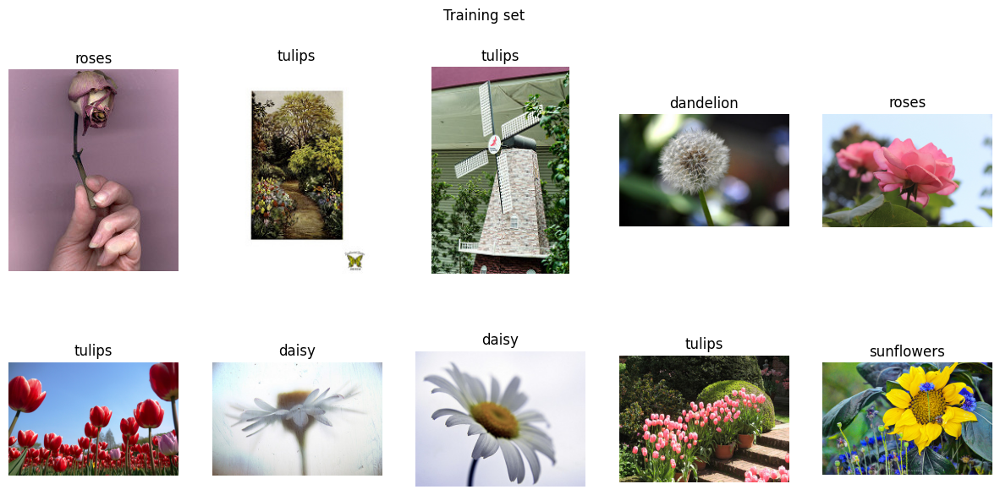

Validation set: 550 samples


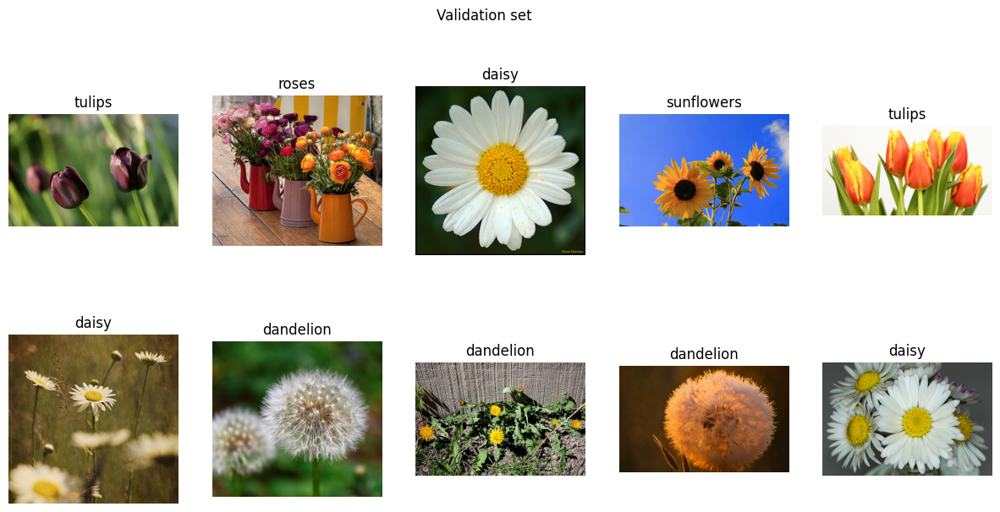

Test set: 367 samples


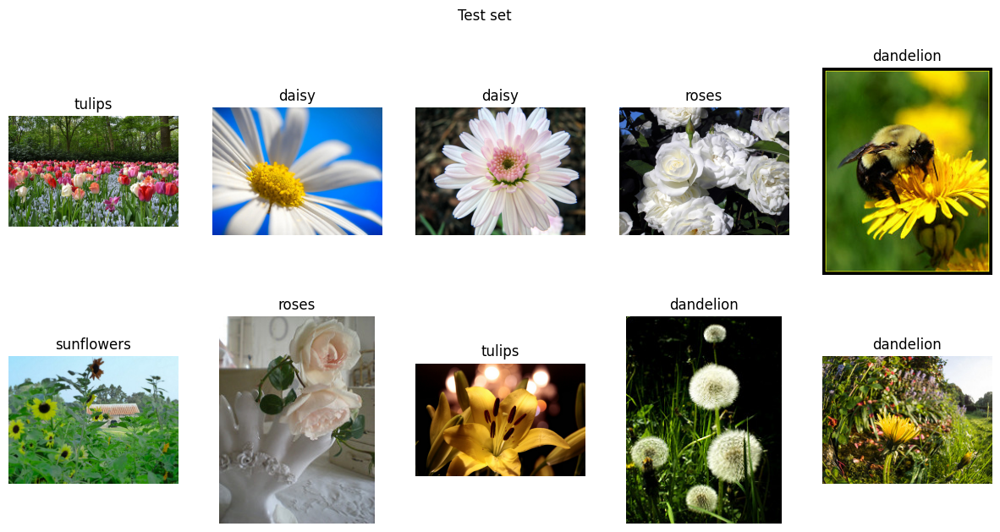

In [10]:
dataset_info(train_set, "Training", class_names)
dataset_info(valid_set, "Validation", class_names)
dataset_info(test_set, "Test", class_names)

If everything worked out fine, you'll have a grid of nicely labeled flower photos as your output:

<center> <img src='https://github.com/gse-unil/2026_MLEES_book/blob/main/live/part-III/_static/6.2-flower-sample-grid-reference.png?raw=1'> </center>

The flowers look very nice! ("*And I'd be pretty bad at classifying them myself...*" - a botanically challenged TA)

However, there is one sore point for our purposes - *the images have different resolutions*. Why is this a sore point? Well, in our architecture we'll eventually flatten our convolutions and connect them to a dense layer, and as such we will need for all of the images to have the same dimensions! (There are other ways to address the issue of resolution, but we won't discuss these for now)

We also note that our `toTensor` transform already scaled the pixel values to fall between 0 and 1 — one fewer thing to worry about compared to the raw 0–255 integers.

Let's write a preprocessing transform that resizes every image to a common size!

## Q4) Write a preprocessing transform that resizes images to 128x128.

*Hint 1: [`torchvision.transforms.v2.Resize((height, width))`](https://docs.pytorch.org/vision/stable/generated/torchvision.transforms.v2.Resize.html) resizes an image tensor to a fixed size.*

*Hint 2: You can chain it onto the `toTensor` pipeline from Q1 using `T.Compose([...])`.*

In [11]:
# Conversion en tenseur, mise à l'échelle [0, 1], puis redimensionnement 128x128
preprocessing_transform = T.Compose([
    T.ToImage(),
    T.ToDtype(torch.float32, scale=True),
    T.Resize((128, 128)),
])

## Q5) Recreate the dataset (and its train/validation/test split) using the new preprocessing transform.

*Hint 1: `random_split()`'s three-way split isn't affected by which transform the underlying dataset uses — as long as you re-create `full_dataset` with `transform=preprocessing_transform` and re-run `random_split()` with the same seed, you'll get the same three subsets, just resized this time.*

In [12]:
full_dataset = torchvision.datasets.ImageFolder(root=flowers_root, transform=preprocessing_transform)

# Même graine => mêmes indices dans chaque sous-ensemble qu'avant
torch.manual_seed(rnd_seed)
train_set, valid_set, test_set = torch.utils.data.random_split(
    full_dataset, [0.75, 0.15, 0.10])

At this point I'd also like to point out that our dataset is not set up to be taken in batches. If you index a single sample, you'll extract a single (image, label) pair — not a batch of them.

In [13]:
image, label = train_set[0]
print(f'Image shape: {image.shape}, Label: {label}')

Image shape: torch.Size([3, 128, 128]), Label: 4


We actually want to work in 32 image batches, so let's go ahead as set up data loaders for our datasets.

## Q6) Wrap each of the training, validation, and test sets in a `DataLoader` with a batch size of 32.

*Hint 1: You can define a `batch_size` variable to guarantee that the batch size is updated for all three loaders if you change the value and rerun this cell.*

*Hint 2: Only the training loader needs `shuffle=True` — we don't need to shuffle validation or test data.*

In [14]:
# Taille de batch (modifiable en un seul endroit)
batch_size = 32

# On mélange uniquement l'entraînement ; validation et test restent dans l'ordre
train_loader = torch.utils.data.DataLoader(train_set, batch_size=batch_size, shuffle=True)
valid_loader = torch.utils.data.DataLoader(valid_set, batch_size=batch_size)
test_loader = torch.utils.data.DataLoader(test_set, batch_size=batch_size)

If we now take a sample batch like we did before, we'll notice that there's now a leading batch dimension in the shape!

In [15]:
images, labels = next(iter(valid_loader))
print(f'Images shape: {images.shape} Labels: {labels.shape}')
print(f'Max pixel value: {images.max()}')

Images shape: torch.Size([32, 3, 128, 128]) Labels: torch.Size([32])
Max pixel value: 1.0


Now that we've verified that our data loaders work as intended, let's go ahead and build our model!

## Model Setup and Training

Let's begin by setting up everything we need to track our runs! This time, we want to work with multiple runs, and in order to visualize them independently in TensorBoard, each run needs to write to its own log directory.

## Q7) Define a function that returns a filepath with the format `'./CNN_logs/run_CURRENT-DATE-AND-TIME'`

*Hint 1: Numpy includes a method to return the current date and time as a datetime64 object. Call the `datetime64` method with `'now'` as an argument on the numpy library, then convert it to a string.*

In [16]:
def get_CNN_logdir():
    # Date et heure actuelles, ex. '2026-11-01T21:56:00'
    # (on remplace ':' par '-' car ce caractère est interdit dans les noms de fichiers Windows)
    time = str(np.datetime64('now')).replace(":", "-")
    run_logdir = os.path.join(os.curdir, "CNN_logs", f"run_{time}")
    return run_logdir

Let's try out our function! It should return something like: `./CNN_logs/run_2022-04-10T18:49`

In [17]:
get_CNN_logdir()

'./CNN_logs/run_2026-11-01T21-15-20'

As in the artificial-neural-networks exercises, we'll track training with a manual early-stopping counter, a checkpoint saved with `torch.save()` whenever the validation loss improves, and a `SummaryWriter` for TensorBoard.

## Q8) Set up the early-stopping counter, best-validation-loss tracker, checkpoint filename, and TensorBoard writer for a CNN model *without* data augmentation.

*Hint 1: See the artificial-neural-networks exercises for the pattern — a `patience` value, a `best_val_loss` initialized to infinity, an `epochs_without_improvement` counter, and a checkpoint filename to pass to `torch.save()`.*

In [18]:
patience = 5                  # nb d'époques sans amélioration avant d'arrêter
best_val_loss = float("inf")  # meilleure perte de validation vue jusqu'ici
epochs_without_improvement = 0
checkpoint_path = "CNN_unaugmented.pt"
writer = torch.utils.tensorboard.SummaryWriter(get_CNN_logdir())

We now have everything we need to track a training run. Let's go ahead and define the model! Though let's go ahead and clean up our random states first for consistency.

In [19]:
# Run this cell
torch.manual_seed(rnd_seed)
np.random.seed(rnd_seed)

## Q9) Define a convolutional neural network model. Do not use data augmentation techniques! We want to use this same architecture + data augmentation later, so we can compare the two.

*Hint 1: There is at least one small, immediate change from the architecture below that will make its performance more effective — see if you can spot it once you've trained it.*

*Hint 2: [`nn.Conv2d`](https://docs.pytorch.org/docs/stable/generated/torch.nn.Conv2d.html) needs an explicit number of input channels — the first convolution's input has 3 (RGB), and every later layer's input channels equal the previous layer's output channels.*

*Hint 3: [`nn.LazyLinear`](https://docs.pytorch.org/docs/stable/generated/torch.nn.LazyLinear.html) infers its input size the first time data flows through it, so you don't need to compute the flattened size by hand after four poolings — unlike `nn.Linear`, which requires it upfront.*

*Hint 4: As in the artificial-neural-networks exercises, leave the very last layer as a plain `nn.LazyLinear`/`nn.Linear` with no activation — `nn.CrossEntropyLoss` expects raw logits, not softmax probabilities.*

In [20]:
# Architecture du CNN (4 blocs convolution + pooling, puis une tête dense).
# On la met dans une fonction pour pouvoir recréer exactement le même modèle
# plus tard (Q13 et rechargement des checkpoints).
def build_cnn():
    return nn.Sequential(
        # Convolution 1 : 3 canaux (RGB) -> 32 cartes de features
        nn.Conv2d(3, 32, kernel_size=3, padding="same"), nn.ReLU(),
        nn.MaxPool2d((2, 2)),          # 128x128 -> 64x64

        # Convolution 2 : 32 -> 64
        nn.Conv2d(32, 64, kernel_size=3, padding="same"), nn.ReLU(),
        nn.MaxPool2d((2, 2)),          # 64x64 -> 32x32

        # Convolution 3 : 64 -> 128
        nn.Conv2d(64, 128, kernel_size=3, padding="same"), nn.ReLU(),
        nn.MaxPool2d((2, 2)),          # 32x32 -> 16x16

        # Convolution 4 : 128 -> 128
        nn.Conv2d(128, 128, kernel_size=3, padding="same"), nn.ReLU(),
        nn.MaxPool2d((2, 2)),          # 16x16 -> 8x8

        nn.Flatten(),                  # 128 * 8 * 8 = 8192 valeurs par image
        nn.LazyLinear(128), nn.ReLU(), # LazyLinear déduit tout seul la taille d'entrée
        nn.Dropout(0.5),               # régularisation : réduit le surapprentissage
        nn.LazyLinear(5),              # 5 classes ; pas d'activation (logits pour CrossEntropyLoss)
    )

model = build_cnn()

In [21]:
# Run one batch through the model to materialize the LazyLinear layers,
# then print the model's structure
model(torch.zeros(1, 3, 128, 128))
print(model)

Sequential(
  (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=same)
  (1): ReLU()
  (2): MaxPool2d(kernel_size=(2, 2), stride=(2, 2), padding=0, dilation=1, ceil_mode=False)
  (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=same)
  (4): ReLU()
  (5): MaxPool2d(kernel_size=(2, 2), stride=(2, 2), padding=0, dilation=1, ceil_mode=False)
  (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=same)
  (7): ReLU()
  (8): MaxPool2d(kernel_size=(2, 2), stride=(2, 2), padding=0, dilation=1, ceil_mode=False)
  (9): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=same)
  (10): ReLU()
  (11): MaxPool2d(kernel_size=(2, 2), stride=(2, 2), padding=0, dilation=1, ceil_mode=False)
  (12): Flatten(start_dim=1, end_dim=-1)
  (13): Linear(in_features=8192, out_features=128, bias=True)
  (14): ReLU()
  (15): Dropout(p=0.5, inplace=False)
  (16): Linear(in_features=128, out_features=5, bias=True)
)


## Q10) Define the loss function, optimizer, and accuracy metric. We recommend `nn.CrossEntropyLoss` as the loss function, `Adam` as the optimizer, and `torchmetrics.Accuracy` for the metric.

In [22]:
# Perte : entropie croisée (attend des logits bruts et des labels entiers)
loss_fn = nn.CrossEntropyLoss()

# Le modèle est déjà "matérialisé" (cellule précédente), on peut donc le déplacer
# sur le GPU avant de créer l'optimiseur
model = model.to(device)
optimizer = torch.optim.Adam(model.parameters())

# Métrique d'exactitude multi-classes (5 espèces de fleurs).
# Une métrique pour la validation, une pour l'entraînement.
accuracy = torchmetrics.Accuracy(task="multiclass", num_classes=5).to(device)
train_accuracy = torchmetrics.Accuracy(task="multiclass", num_classes=5).to(device)

## Q11) Train the CNN model!

*Hint 1: Write the same training-and-validation loop as in the artificial-neural-networks exercises: a training phase over `train_loader`, a validation phase over `valid_loader` inside `with torch.no_grad():`, TensorBoard logging with `writer.add_scalar()`, and checkpointing/early stopping based on `patience`.*

*Hint 2: This dataset is larger and the model deeper than in the MNIST exercises, so don't be surprised if training takes a while — especially without a GPU.*

In [23]:
n_epochs = 30  # nombre maximal d'époques (l'early stopping peut arrêter avant)

for epoch in range(n_epochs):
    # ----- Phase d'entraînement -----
    model.train()                       # active le dropout
    train_losses = []
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)  # données sur le GPU
        optimizer.zero_grad()           # remise à zéro des gradients
        y_pred = model(images)          # passe avant -> logits
        loss = loss_fn(y_pred, labels)  # calcul de la perte
        loss.backward()                 # rétropropagation
        optimizer.step()                # mise à jour des poids
        train_losses.append(loss.item())
        train_accuracy.update(y_pred, labels)

    # ----- Phase de validation -----
    model.eval()                        # désactive le dropout
    val_losses = []
    with torch.no_grad():               # pas de gradients : plus rapide, moins de mémoire
        for images, labels in valid_loader:
            images, labels = images.to(device), labels.to(device)
            y_pred = model(images)
            val_losses.append(loss_fn(y_pred, labels).item())
            accuracy.update(y_pred, labels)

    # Moyennes de l'époque
    train_loss = np.mean(train_losses)
    train_acc = train_accuracy.compute().item()
    val_loss = np.mean(val_losses)
    val_accuracy = accuracy.compute().item()
    train_accuracy.reset()              # on remet les métriques à zéro pour l'époque suivante
    accuracy.reset()

    print(f"Epoch {epoch + 1:2d} | train loss {train_loss:.4f} acc {train_acc:.4f} "
          f"| val loss {val_loss:.4f} acc {val_accuracy:.4f}")

    # Journalisation TensorBoard
    writer.add_scalar("Loss/train", train_loss, epoch)
    writer.add_scalar("Accuracy/train", train_acc, epoch)
    writer.add_scalar("Loss/validation", val_loss, epoch)
    writer.add_scalar("Accuracy/validation", val_accuracy, epoch)

    # Checkpoint + early stopping
    if val_loss < best_val_loss:        # amélioration : on sauvegarde le meilleur modèle
        best_val_loss = val_loss
        epochs_without_improvement = 0
        torch.save(model.state_dict(), checkpoint_path)
    else:                               # pas d'amélioration
        epochs_without_improvement += 1
        if epochs_without_improvement >= patience:
            print(f"Early stopping à l'époque {epoch + 1}")
            break

writer.close()

Epoch  1 | train loss 1.3886 acc 0.3720 | val loss 1.3049 acc 0.4527
Epoch  2 | train loss 1.1844 acc 0.4926 | val loss 1.0842 acc 0.5873
Epoch  3 | train loss 1.0798 acc 0.5710 | val loss 0.9811 acc 0.6036
Epoch  4 | train loss 0.9956 acc 0.6117 | val loss 0.9992 acc 0.6327
Epoch  5 | train loss 0.9607 acc 0.6251 | val loss 0.9037 acc 0.6909
Epoch  6 | train loss 0.9131 acc 0.6357 | val loss 0.9367 acc 0.6982
Epoch  7 | train loss 0.8578 acc 0.6556 | val loss 0.8487 acc 0.6764
Epoch  8 | train loss 0.7943 acc 0.6960 | val loss 0.8052 acc 0.7073
Epoch  9 | train loss 0.7308 acc 0.7185 | val loss 0.8200 acc 0.6964
Epoch 10 | train loss 0.6837 acc 0.7258 | val loss 0.8051 acc 0.7200
Epoch 11 | train loss 0.6927 acc 0.7541 | val loss 0.8205 acc 0.7164
Epoch 12 | train loss 0.8296 acc 0.6803 | val loss 0.7981 acc 0.7200
Epoch 13 | train loss 0.6108 acc 0.7479 | val loss 0.8830 acc 0.7018
Epoch 14 | train loss 0.5659 acc 0.7871 | val loss 0.8440 acc 0.7036
Epoch 15 | train loss 0.5095 acc 0

In [ ]:
# Result of the first run (no augmentation):
# - The model learns the training images very well (train accuracy ~0.90),
#   but validation accuracy stays around 0.72-0.76. This is overfitting.
# - The validation loss is best at epoch 16 (0.75) and then goes up,
#   while the training loss keeps going down.
# - Early stopping stopped training at epoch 21 (16 + patience of 5). Meilleur score a epoch 16 val_loss les 5 d'après pas mieux
#   The best model (epoch 16) is saved in CNN_unaugmented.pt.
# - Next step: data augmentation (flip + rotation) should reduce the gap
#   between train and validation, and give a lower validation loss.

Well, the performance of our CNN is likely underwhelming:

<center> <img src='https://github.com/gse-unil/2026_MLEES_book/blob/main/live/part-III/_static/6.2-tensorboard-unaugmented-reference.png?raw=1'> </center>

The model didn't have too hard a time learning on the training set, but the validation loss quickly diverged and we started overfitting our training data. 😯

A common way to try to address this is by augmenting our training data - we can flip and rotate our images and it shouldn't make too large a difference.

> "A rose by any other name would smell as sweet" - *Shakespeare*

> "An upside down rose is still a rose" - *A significantly less talented poet than Shakespeare*

In [24]:
# Run this cell
torch.manual_seed(rnd_seed)
np.random.seed(rnd_seed)

## Q12) Set up the early-stopping counter, best-validation-loss tracker, checkpoint filename, and TensorBoard writer for a CNN model *with* data augmentation.

In [25]:
patience = 5
best_val_loss = float("inf")
epochs_without_improvement = 0
checkpoint_path = "CNN_augmented.pt"
writer = torch.utils.tensorboard.SummaryWriter(get_CNN_logdir())

In [ ]:
# Data augmentation (training set only):
# - RandomHorizontalFlip: flips the image left-right (50% chance).
# - RandomRotation(30): turns the image by a random angle between -30 and +30 degrees.
# Why? Our model overfits: it memorizes the training images.
# With augmentation, the model sees a slightly different version of each
# image at every epoch, so it has to learn what makes a flower a flower
# (not the exact position of the petals).
# A flipped or tilted rose is still a rose, so the label does not change.
# We do NOT augment the validation and test sets, because we want to
# measure the performance on real, unchanged images.
# Expected result: lower train accuracy, but equal or better validation/test accuracy.

## Q13) Train an identical model to that defined in Q9, with the exception of `RandomHorizontalFlip` and `RandomRotation` augmentation transforms added to the *training set's* preprocessing.

*Hint 1: Unlike Keras, where `RandomFlip`/`RandomRotation` are layers inside the model, PyTorch applies data augmentation as part of the dataset's `transform` — so this means building a second `ImageFolder` (with its own `random_split`, same seed) whose transform chains [`T.RandomHorizontalFlip()`](https://docs.pytorch.org/vision/stable/generated/torchvision.transforms.v2.RandomHorizontalFlip.html) and [`T.RandomRotation(degrees)`](https://docs.pytorch.org/vision/stable/generated/torchvision.transforms.v2.RandomRotation.html) onto the Q5 preprocessing pipeline, then wrapping its *training* subset in a new `DataLoader`. The validation and test loaders should stay exactly as they were — we don't want to augment the data we evaluate on!*

In [26]:
# L'augmentation est appliquée sur l'image PIL AVANT la conversion en tenseur.
augmented_transform = T.Compose([
    T.RandomHorizontalFlip(),   # retournement horizontal aléatoire (p=0.5)
    T.RandomRotation(30),       # rotation aléatoire entre -30° et +30°
    T.ToImage(), T.ToDtype(torch.float32, scale=True), T.Resize((128, 128)),  # même prétraitement qu'en Q4
])

In [27]:
# Dataset dont les images sont augmentées à chaque accès
augmented_dataset = torchvision.datasets.ImageFolder(root=flowers_root, transform=augmented_transform)

# Même graine => exactement les mêmes images dans le train set qu'avant.
# On ne garde que le train set : validation et test restent non augmentés.
torch.manual_seed(rnd_seed)
augmented_train_set, _, _ = torch.utils.data.random_split(
    augmented_dataset, [0.75, 0.15, 0.10])

In [28]:
# Seul le loader d'entraînement change ; valid_loader et test_loader restent identiques
train_loader = torch.utils.data.DataLoader(augmented_train_set, batch_size=batch_size, shuffle=True)

In [29]:
# Architecture strictement identique à Q9 (on réutilise la fonction définie plus haut)
model = build_cnn()

In [30]:
# Run one batch through the model to materialize the LazyLinear layers,
# then print the model's structure
model(torch.zeros(1, 3, 128, 128))
print(model)

Sequential(
  (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=same)
  (1): ReLU()
  (2): MaxPool2d(kernel_size=(2, 2), stride=(2, 2), padding=0, dilation=1, ceil_mode=False)
  (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=same)
  (4): ReLU()
  (5): MaxPool2d(kernel_size=(2, 2), stride=(2, 2), padding=0, dilation=1, ceil_mode=False)
  (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=same)
  (7): ReLU()
  (8): MaxPool2d(kernel_size=(2, 2), stride=(2, 2), padding=0, dilation=1, ceil_mode=False)
  (9): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=same)
  (10): ReLU()
  (11): MaxPool2d(kernel_size=(2, 2), stride=(2, 2), padding=0, dilation=1, ceil_mode=False)
  (12): Flatten(start_dim=1, end_dim=-1)
  (13): Linear(in_features=8192, out_features=128, bias=True)
  (14): ReLU()
  (15): Dropout(p=0.5, inplace=False)
  (16): Linear(in_features=128, out_features=5, bias=True)
)


## Q14) Define the loss function, optimizer, and accuracy metric, exactly as in Q10.

In [31]:
# Comme en Q10 -- Perte : entropie croisée (attend des logits bruts et des labels entiers)
loss_fn = nn.CrossEntropyLoss()

# Le modèle est déjà "matérialisé" (cellule précédente), on peut donc le déplacer
# sur le GPU avant de créer l'optimiseur
model = model.to(device)
optimizer = torch.optim.Adam(model.parameters())

# Métrique d'exactitude multi-classes (5 espèces de fleurs).
# Une métrique pour la validation, une pour l'entraînement.
accuracy = torchmetrics.Accuracy(task="multiclass", num_classes=5).to(device)
train_accuracy = torchmetrics.Accuracy(task="multiclass", num_classes=5).to(device)

In [32]:
n_epochs = 30  # nombre maximal d'époques (l'early stopping peut arrêter avant)

for epoch in range(n_epochs):
    # ----- Phase d'entraînement -----
    model.train()                       # active le dropout
    train_losses = []
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)  # données sur le GPU
        optimizer.zero_grad()           # remise à zéro des gradients
        y_pred = model(images)          # passe avant -> logits
        loss = loss_fn(y_pred, labels)  # calcul de la perte
        loss.backward()                 # rétropropagation
        optimizer.step()                # mise à jour des poids
        train_losses.append(loss.item())
        train_accuracy.update(y_pred, labels)

    # ----- Phase de validation -----
    model.eval()                        # désactive le dropout
    val_losses = []
    with torch.no_grad():               # pas de gradients : plus rapide, moins de mémoire
        for images, labels in valid_loader:
            images, labels = images.to(device), labels.to(device)
            y_pred = model(images)
            val_losses.append(loss_fn(y_pred, labels).item())
            accuracy.update(y_pred, labels)

    # Moyennes de l'époque
    train_loss = np.mean(train_losses)
    train_acc = train_accuracy.compute().item()
    val_loss = np.mean(val_losses)
    val_accuracy = accuracy.compute().item()
    train_accuracy.reset()              # on remet les métriques à zéro pour l'époque suivante
    accuracy.reset()

    print(f"Epoch {epoch + 1:2d} | train loss {train_loss:.4f} acc {train_acc:.4f} "
          f"| val loss {val_loss:.4f} acc {val_accuracy:.4f}")

    # Journalisation TensorBoard
    writer.add_scalar("Loss/train", train_loss, epoch)
    writer.add_scalar("Accuracy/train", train_acc, epoch)
    writer.add_scalar("Loss/validation", val_loss, epoch)
    writer.add_scalar("Accuracy/validation", val_accuracy, epoch)

    # Checkpoint + early stopping
    if val_loss < best_val_loss:        # amélioration : on sauvegarde le meilleur modèle
        best_val_loss = val_loss
        epochs_without_improvement = 0
        torch.save(model.state_dict(), checkpoint_path)
    else:                               # pas d'amélioration
        epochs_without_improvement += 1
        if epochs_without_improvement >= patience:
            print(f"Early stopping à l'époque {epoch + 1}")
            break

writer.close()

Epoch  1 | train loss 1.4330 acc 0.3476 | val loss 1.2361 acc 0.4855
Epoch  2 | train loss 1.1914 acc 0.4973 | val loss 1.1342 acc 0.6073
Epoch  3 | train loss 1.0696 acc 0.5721 | val loss 1.0568 acc 0.6127
Epoch  4 | train loss 1.0551 acc 0.5743 | val loss 1.0666 acc 0.6145
Epoch  5 | train loss 1.0652 acc 0.5667 | val loss 0.9037 acc 0.6473
Epoch  6 | train loss 0.9455 acc 0.6153 | val loss 0.8251 acc 0.6545
Epoch  7 | train loss 0.9095 acc 0.6411 | val loss 0.8737 acc 0.6582
Epoch  8 | train loss 0.8470 acc 0.6742 | val loss 0.8253 acc 0.6873
Epoch  9 | train loss 0.8658 acc 0.6502 | val loss 0.8053 acc 0.6964
Epoch 10 | train loss 0.8393 acc 0.6836 | val loss 0.7857 acc 0.7055
Epoch 11 | train loss 0.8140 acc 0.6803 | val loss 0.8436 acc 0.7055
Epoch 12 | train loss 0.8071 acc 0.6843 | val loss 0.7598 acc 0.7000
Epoch 13 | train loss 0.8798 acc 0.6669 | val loss 0.7428 acc 0.7273
Epoch 14 | train loss 0.7492 acc 0.7047 | val loss 0.7010 acc 0.7164
Epoch 15 | train loss 0.7287 acc 0

In [ ]:
# Result of the run WITH augmentation:
# - Best model at epoch 23 (val loss 0.6153). Training stopped at epoch 28 (23 + patience of 5).
# - Train accuracy (~0.77) and validation accuracy (~0.76) are now very close,
#   so there is almost no overfitting anymore.
# - The validation loss is clearly better than without augmentation (0.62 vs 0.75).
# - Validation accuracy is only a bit better, so the final comparison
#   is done on the test set below.

In [ ]:
# Validation loss = the average error of the model on images it does NOT train on.
# Low value = the model gives high scores to the right flower.
# It is a good way to see if the model works on new images (generalization).
# If train loss goes down but validation loss goes up -> overfitting.

If everything went according to plan, your model including data augmentation should perform a little better:

<center> <img src='https://github.com/gse-unil/2026_MLEES_book/blob/main/live/part-III/_static/6.2-tensorboard-augmented-reference.png?raw=1'> </center>

Now let's run tensorboard and compare your two runs!

In [35]:
%tensorboard --logdir=./CNN_logs --port=6006

Reusing TensorBoard on port 6006 (pid 8038), started 0:00:31 ago. (Use '!kill 8038' to kill it.)

<IPython.core.display.Javascript object>

If everything went well, the model trained on the augmented data should have a lower accuracy on the training set compared to the original, but the better of the two should generalize better to unseen data — i.e. score a higher accuracy on the validation and test sets. Let's check by reloading both models' best checkpoints and evaluating them on the test set.

In [36]:
# Rechargement du modèle sans augmentation
non_aug_model = build_cnn()
non_aug_model(torch.zeros(1, 3, 128, 128))  # une passe pour matérialiser les LazyLinear
non_aug_model.load_state_dict(torch.load("CNN_unaugmented.pt", map_location=device, weights_only=True))
non_aug_model = non_aug_model.to(device)
non_aug_model.eval()

Sequential(
  (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=same)
  (1): ReLU()
  (2): MaxPool2d(kernel_size=(2, 2), stride=(2, 2), padding=0, dilation=1, ceil_mode=False)
  (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=same)
  (4): ReLU()
  (5): MaxPool2d(kernel_size=(2, 2), stride=(2, 2), padding=0, dilation=1, ceil_mode=False)
  (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=same)
  (7): ReLU()
  (8): MaxPool2d(kernel_size=(2, 2), stride=(2, 2), padding=0, dilation=1, ceil_mode=False)
  (9): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=same)
  (10): ReLU()
  (11): MaxPool2d(kernel_size=(2, 2), stride=(2, 2), padding=0, dilation=1, ceil_mode=False)
  (12): Flatten(start_dim=1, end_dim=-1)
  (13): Linear(in_features=8192, out_features=128, bias=True)
  (14): ReLU()
  (15): Dropout(p=0.5, inplace=False)
  (16): Linear(in_features=128, out_features=5, bias=True)
)

In [37]:
# Rechargement du modèle avec augmentation
aug_model = build_cnn()
aug_model(torch.zeros(1, 3, 128, 128))      # matérialisation des LazyLinear
aug_model.load_state_dict(torch.load("CNN_augmented.pt", map_location=device, weights_only=True))
aug_model = aug_model.to(device)
aug_model.eval()

Sequential(
  (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=same)
  (1): ReLU()
  (2): MaxPool2d(kernel_size=(2, 2), stride=(2, 2), padding=0, dilation=1, ceil_mode=False)
  (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=same)
  (4): ReLU()
  (5): MaxPool2d(kernel_size=(2, 2), stride=(2, 2), padding=0, dilation=1, ceil_mode=False)
  (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=same)
  (7): ReLU()
  (8): MaxPool2d(kernel_size=(2, 2), stride=(2, 2), padding=0, dilation=1, ceil_mode=False)
  (9): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=same)
  (10): ReLU()
  (11): MaxPool2d(kernel_size=(2, 2), stride=(2, 2), padding=0, dilation=1, ceil_mode=False)
  (12): Flatten(start_dim=1, end_dim=-1)
  (13): Linear(in_features=8192, out_features=128, bias=True)
  (14): ReLU()
  (15): Dropout(p=0.5, inplace=False)
  (16): Linear(in_features=128, out_features=5, bias=True)
)

In [39]:
# Évaluation des deux modèles sur le jeu de test
for name, model in [("Unaugmented", non_aug_model), ("Augmented", aug_model)]:
    accuracy.reset()
    with torch.no_grad():
        for images, labels in test_loader:
            images, labels = images.to(device), labels.to(device)
            y_pred = model(images)
            accuracy.update(y_pred, labels)
    print(f"{name} model test accuracy: {accuracy.compute().item():.4f}")

Unaugmented model test accuracy: 0.7330
Augmented model test accuracy: 0.7548


## Conclusion

**What we did**
We trained a convolutional neural network (CNN) to classify flower photos into 5 species
(daisy, dandelion, rose, sunflower, tulip). We split the data into training (75%),
validation (15%) and test (10%) sets, resized all images to 128x128, and trained the
same model twice: once without data augmentation and once with it (random flip and
rotation on the training set only). We used cross-entropy loss, the Adam optimizer,
early stopping with checkpoints, and TensorBoard to follow the runs.

**What we observed**
- Without augmentation, the model overfitted. Train accuracy reached about 0.90, but
  validation accuracy stayed around 0.72-0.76. The validation loss was best at epoch 16
  (0.75) and then went up, so early stopping stopped the training at epoch 21.
- With augmentation, train accuracy was lower (about 0.77) but close to validation
  accuracy (about 0.76). The validation loss was clearly better (0.62 at epoch 23).
  The gap between training and validation almost disappeared.
- On the test set (images never used for training or for choosing the model), the
  models got 0.73 (without augmentation) and 0.75 (with augmentation).

**What we learned**
- A CNN can learn to recognize flowers from images, but with only ~3,600 training
  images it quickly memorizes them.
- Training accuracy alone is misleading. We need a validation set to see if the model
  works on new images, and a test set for a final, honest score.
- Data augmentation is a cheap way to reduce overfitting: it gives the model many
  variations of the same images, so it learns the shape and color of the flowers
  instead of memorizing photos. It only works if the transformation does not change
  the label (a flipped rose is still a rose).
- Early stopping and checkpoints save the best model and avoid wasting time on epochs
  that make the model worse.
- TensorBoard makes it easy to compare runs and to spot overfitting on the curves.

**Limits and next steps**
The accuracy is still limited (about 0.76 on validation), and the model underfits a
little: even the training accuracy is only about 0.77 with augmentation. To improve it,
we could use a deeper network or batch normalization, more training epochs with a
larger patience, other augmentations (zoom, brightness), or transfer learning with a
network already trained on a large dataset such as ImageNet.